# Notebook 20b — Wu 2003 CSTR-Column-Recycle: Model Verification for S-B3

## Purpose

This notebook mirrors notebook 20's model-verification flow, but for the reduced-scope
**S-B3** framing. S-B3 is **not** a new physical plant or a new control structure. It reuses
the existing Wu2003 `S-B` simulator exactly, but narrows the manuscript scope so that
feed quality (`z_A0_eff`) is treated as **exogenous** rather than as a plant fault variable.


That reduced scope changes two things only:
1. the retained fault scenarios exclude any case with a feed-fault component,
2. the endogenous inference / attribution target is reduced to `[alpha, beta_r, eta_col, xi_reb]`.

The model equations, QSS column block, and raw observation channels remain the same as in
notebook 20. This notebook therefore verifies two things at once:
1. the original Wu2003 implementation is still locally consistent under the narrowed scope,
2. the reduced scenario catalogue remains physically meaningful rather than a trivial subset.

## Verification objectives

| # | Check | Section | Reduced-scope purpose |
|---|-------|---------|-----------------------|
| 1 | Arrhenius kinetics unchanged | §2 | reduced scope must not alter reactor physics |
| 2 | QSS column nominal + `eta_col` sensitivity unchanged | §3 | reduced scope must not alter column physics |
| 3 | Reduced scenario catalogue (`S-B3`) is exactly the no-feed subset | §4 | confirms the scope narrowing is implemented as intended |
| 4 | Nominal `S-B` warm start remains finite and reusable | §5 | ensures the reduced workflow can share the original simulator |
| 5 | Snowball dynamics still appear under catalyst decay | §6 | confirms the reduced problem still contains the main reactor-side nonlinearity |
| 6 | Control masking still appears under jacket fouling | §7 | confirms the reduced problem still contains the main closed-loop masking effect |
| 7 | W7 vs W12 still preview the cross-unit ambiguity inside the reduced scope | §8 | confirms the reduced problem is still inferentially nontrivial |

## Section 1 — Imports

### Observable channels and reduced scope

The simulator still produces the same **12-channel raw observation vector** as notebook 20:
`[T_r, T_j, Q_j, x_D, x_B, T_reb, Q_reb, F_R_norm, F_B_norm, R_norm, V_norm, z_A]`.

S-B3 does **not** remove `z_A0_eff` from the plant equations; instead, it removes it from the
*public fault taxonomy and inference target* by fixing it to its nominal value whenever a strict
4-D `S-B3` wrapper is used. This notebook therefore uses the new strict helper surface in
`cstr_sbi.recycle.sb3` so that all reduced-scope calls accept only 4-D endogenous parameters or
already-filtered no-feed scenarios.

### Endogenous fault parameterisation (4-D)

| Parameter | Symbol | Physical meaning | Main reduced-scope role |
|-----------|--------|------------------|-------------------------|
| Catalyst activity | alpha | reaction-rate degradation | reactor snowball driver |
| Jacket fouling | beta_r | reactor heat-transfer degradation | masked reactor-side fault |
| Tray efficiency | eta_col | column separation degradation | column-side snowball driver |
| Reboiler fouling | xi_reb | reboiler duty degradation | column-side energy-demand driver |

In [9]:
import sys; sys.path.insert(0, '../src')
import importlib
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax.numpy as jnp

from cstr_sbi.recycle.physics import (
    R_GAS, EA, K0, T_SS, K_SS, X_D_NOM, column_qss,
)
from cstr_sbi.recycle.scenarios import CLOSED_LOOP_NAMES
import cstr_sbi.recycle.sb3 as sb3
sb3 = importlib.reload(sb3)
from cstr_sbi.recycle.sb3 import (
    SB3_EXCLUDED_SCENARIOS,
    CLOSED_LOOP_NAMES_SB3,
    SB3_PARAM_NAMES,
    FAULT_UNITS_SB3,
    list_closed_loop_sb3,
    nominal_warm_start_sb3,
    deterministic_window_sb3,
    fault_unit_sb3_truth,
)

FIGURES = pathlib.Path('../figures'); FIGURES.mkdir(exist_ok=True)
OI = ['#000000', '#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7']

scenarios = list_closed_loop_sb3()
y0_sb3 = nominal_warm_start_sb3()
print('Imports OK')
print('Retained scenarios:', CLOSED_LOOP_NAMES_SB3)
print('Excluded scenarios:', SB3_EXCLUDED_SCENARIOS)
print('Reduced fault units:', FAULT_UNITS_SB3)
print('Endogenous parameters:', SB3_PARAM_NAMES)

Imports OK
Retained scenarios: ['W1_healthy', 'W2_cat_mild', 'W3_cat_severe', 'W4_cat_threshold', 'W5_jacket_mild', 'W6_jacket_severe', 'W7_col_eff_mild', 'W9_reb_fouling', 'W11_reactor_combined', 'W12_snowball_compound', 'W15_snowball_threshold', 'W16_full_multi']
Excluded scenarios: ('W10_feed_impurity', 'W13_cat_feed')
Reduced fault units: ['healthy', 'reactor', 'column', 'multi']
Endogenous parameters: ('alpha', 'beta_r', 'eta_col', 'xi_reb')


## Section 2 — Kinetics sanity check

The reduced `S-B3` scope must not alter the reactor kinetics. The same Arrhenius check used in
notebook 20 should still hold exactly: at the nominal steady-state temperature `T_SS = 342.26 K`,
the first-order rate constant should remain `k_SS ≈ 0.33 /h`.

## Section 3 — QSS column nominal check and `eta_col` sensitivity

Likewise, the reduced scope must not alter the QSS column block. Since `z_A0_eff` is held fixed
at nominal in `S-B3`, the reduced problem still relies on the same column mapping from reactor
composition to `x_D`, `x_B`, and boilup-sensitive proxies. The nominal QSS column evaluation and
the `eta_col` sweep should therefore match notebook 20 qualitatively.

k(T_SS=342.26 K) = 0.3300 /h  (expected ~0.33)
Kinetics check PASSED

=== Nominal QSS column (z_F=0.50, eta_col=1.0) ===
  x_D    = 0.9416  (expected ~0.95)
  x_B    = 0.01957  (expected ~0.011)
  D_frac = 0.5210  (expected ~0.521)


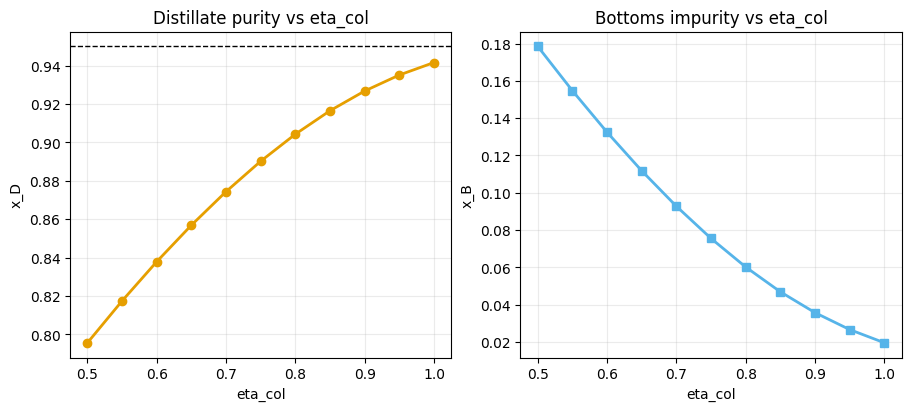

Saved nb20b_col_sensitivity_sb3.png


In [10]:
k_check = float(K0 * jnp.exp(-EA / (R_GAS * T_SS)))
print(f'k(T_SS={T_SS:.2f} K) = {k_check:.4f} /h  (expected ~0.33)')
assert abs(k_check - float(K_SS)) < 0.01, f'Kinetics mismatch: {k_check:.4f} vs {float(K_SS):.4f}'
print('Kinetics check PASSED')

result = column_qss(z_F=0.500, eta_col=1.0)
x_D_nom = float(result[0])
x_B_nom = float(result[1])
D_frac_nom = float(result[2])
print('\n=== Nominal QSS column (z_F=0.50, eta_col=1.0) ===')
print(f'  x_D    = {x_D_nom:.4f}  (expected ~0.95)')
print(f'  x_B    = {x_B_nom:.5f}  (expected ~0.011)')
print(f'  D_frac = {D_frac_nom:.4f}  (expected ~0.521)')

eta_vals = np.linspace(0.5, 1.0, 11)
xd_vals, xb_vals = [], []
for eta in eta_vals:
    res = column_qss(z_F=0.500, eta_col=float(eta))
    xd_vals.append(float(res[0]))
    xb_vals.append(float(res[1]))

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
axes[0].plot(eta_vals, xd_vals, 'o-', color=OI[1], lw=2)
axes[0].axhline(float(X_D_NOM), color=OI[0], ls='--', lw=1.0)
axes[0].set_xlabel('eta_col')
axes[0].set_ylabel('x_D')
axes[0].set_title('Distillate purity vs eta_col')
axes[0].grid(True, alpha=0.25)
axes[1].plot(eta_vals, xb_vals, 's-', color=OI[2], lw=2)
axes[1].set_xlabel('eta_col')
axes[1].set_ylabel('x_B')
axes[1].set_title('Bottoms impurity vs eta_col')
axes[1].grid(True, alpha=0.25)
plt.savefig(FIGURES / 'nb20b_col_sensitivity_sb3.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved nb20b_col_sensitivity_sb3.png')

## Section 4 — Reduced scenario catalogue

The original closed-loop Wu2003 catalogue used 14 retained scenarios. Under `S-B3`, only the
feed-containing cases are removed: `W10_feed_impurity` and `W13_cat_feed`. The remaining
12-scenario subset must still span all reduced fault units: `healthy`, `reactor`, `column`,
and `multi`.

## Section 5 — Nominal steady-state warm start

The strict `S-B3` wrapper should still reuse the original `S-B` nominal warm start, because the
underlying simulator is unchanged. This check makes that explicit and records the relevant state
values used as the base for downstream step tests.

In [11]:
catalogue_df = pd.DataFrame([
    {
        'scenario': sc.name,
        'fault_unit_sb3': fault_unit_sb3_truth(np.asarray(sc.theta())[:4]),
        'alpha': float(sc.alpha),
        'beta_r': float(sc.beta_r),
        'eta_col': float(sc.eta_col),
        'xi_reb': float(sc.xi_reb),
    }
    for sc in scenarios
]).sort_values(['fault_unit_sb3', 'scenario']).reset_index(drop=True)
print('Retained original closed-loop names:', len(CLOSED_LOOP_NAMES), '->', len(CLOSED_LOOP_NAMES_SB3))
catalogue_df

print('\nNominal S-B3 warm start (same physical state as S-B with z_A0_eff fixed nominal):')
print(f'  z_A={float(y0_sb3[0]):.4f}')
print(f'  T_r={float(y0_sb3[1]):.2f} K')
print(f'  T_j={float(y0_sb3[2]):.2f} K')
print(f'  R={float(y0_sb3[4]):.4f}')
print(f'  V={float(y0_sb3[5]):.4f}')

Retained original closed-loop names: 14 -> 12

Nominal S-B3 warm start (same physical state as S-B with z_A0_eff fixed nominal):
  z_A=0.5099
  T_r=342.26 K
  T_j=331.52 K
  R=2.1980
  V=0.9108


## Section 6 — Step test: catalyst decay (W3, `alpha = 0.65`)

This mirrors notebook 20's snowball-dynamics check. The reduced-scope reframing should not
remove the main reactor-side nonlinearity: a loss of catalyst activity still lowers per-pass
conversion and should increase the recycle burden.

## Section 7 — Step test: jacket fouling (W6, `beta_r = 0.60`)

This mirrors notebook 20's control-masking check. Jacket fouling is retained in `S-B3` and should
still appear primarily through `T_j` / `Q_j` while `T_r` remains tightly regulated.

## Section 8 — Reduced-scope ambiguity preview (`W7` vs `W12`)

The reduced `S-B3` scope removes feed confounding, but it does **not** remove the remaining
reactor/column ambiguity inside the retained endogenous parameter set. Comparing `W7_col_eff_mild`
against `W12_snowball_compound` gives a compact preview of why the reduced problem is still
nontrivial for SBI.

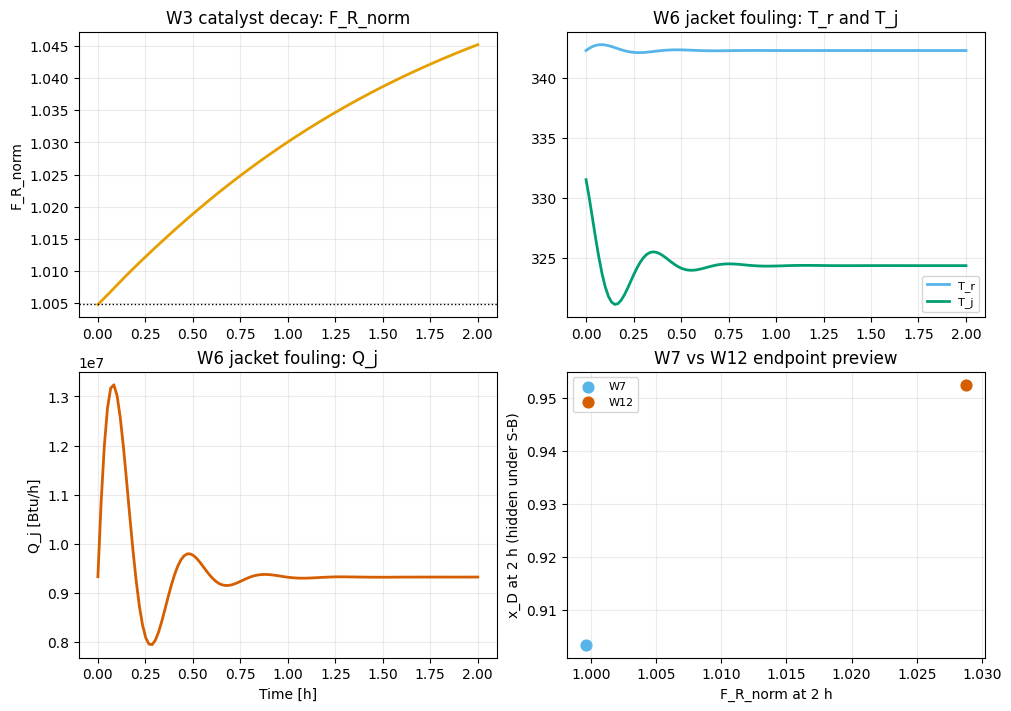

W3 final F_R_norm: 1.04521644115448
W6 max |T_r - T_r(0)|: 0.48822021484375
W6 T_j shift: -7.14837646484375
W7 endpoint (F_R_norm, x_D): 0.9996379017829895 0.9034246206283569
W12 endpoint (F_R_norm, x_D): 1.0287768840789795 0.9525318145751953


In [12]:
sc_w3 = next(sc for sc in scenarios if sc.name == 'W3_cat_severe')
sc_w6 = next(sc for sc in scenarios if sc.name == 'W6_jacket_severe')
sc_w7 = next(sc for sc in scenarios if sc.name == 'W7_col_eff_mild')
sc_w12 = next(sc for sc in scenarios if sc.name == 'W12_snowball_compound')

t_h, raw_w3 = deterministic_window_sb3(sc_w3, y0=y0_sb3)
_, raw_w6 = deterministic_window_sb3(sc_w6, y0=y0_sb3)
_, raw_w7 = deterministic_window_sb3(sc_w7, y0=y0_sb3)
_, raw_w12 = deterministic_window_sb3(sc_w12, y0=y0_sb3)
raw_w3 = np.asarray(raw_w3)
raw_w6 = np.asarray(raw_w6)
raw_w7 = np.asarray(raw_w7)
raw_w12 = np.asarray(raw_w12)

fig, axes = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
axes[0, 0].plot(t_h, raw_w3[:, 7], color=OI[1], lw=2)
axes[0, 0].axhline(raw_w3[0, 7], color=OI[0], ls=':', lw=1)
axes[0, 0].set_title('W3 catalyst decay: F_R_norm')
axes[0, 0].set_ylabel('F_R_norm')
axes[0, 0].grid(True, alpha=0.25)

axes[0, 1].plot(t_h, raw_w6[:, 0], color=OI[2], lw=2, label='T_r')
axes[0, 1].plot(t_h, raw_w6[:, 1], color=OI[3], lw=2, label='T_j')
axes[0, 1].set_title('W6 jacket fouling: T_r and T_j')
axes[0, 1].legend(fontsize=8)
axes[0, 1].grid(True, alpha=0.25)

axes[1, 0].plot(t_h, raw_w6[:, 2], color=OI[6], lw=2)
axes[1, 0].set_title('W6 jacket fouling: Q_j')
axes[1, 0].set_xlabel('Time [h]')
axes[1, 0].set_ylabel('Q_j [Btu/h]')
axes[1, 0].grid(True, alpha=0.25)

axes[1, 1].scatter(raw_w7[-1, 7], raw_w7[-1, 3], color=OI[2], s=60, label='W7')
axes[1, 1].scatter(raw_w12[-1, 7], raw_w12[-1, 3], color=OI[6], s=60, label='W12')
axes[1, 1].set_title('W7 vs W12 endpoint preview')
axes[1, 1].set_xlabel('F_R_norm at 2 h')
axes[1, 1].set_ylabel('x_D at 2 h (hidden under S-B)')
axes[1, 1].legend(fontsize=8)
axes[1, 1].grid(True, alpha=0.25)

plt.savefig(FIGURES / 'nb20b_sb3_verification_panels.png', dpi=150, bbox_inches='tight')
plt.show()

print('W3 final F_R_norm:', float(raw_w3[-1, 7]))
print('W6 max |T_r - T_r(0)|:', float(np.max(np.abs(raw_w6[:, 0] - raw_w6[0, 0]))))
print('W6 T_j shift:', float(raw_w6[-1, 1] - raw_w6[0, 1]))
print('W7 endpoint (F_R_norm, x_D):', float(raw_w7[-1, 7]), float(raw_w7[-1, 3]))
print('W12 endpoint (F_R_norm, x_D):', float(raw_w12[-1, 7]), float(raw_w12[-1, 3]))

### Results commentary

- The Arrhenius and QSS column checks should match notebook 20 qualitatively because `S-B3` does
  not alter the plant equations.
- The reduced catalogue should show exactly 12 retained scenarios spanning `healthy`, `reactor`,
  `column`, and `multi`.
- `W3` should still show a recycle increase (snowball), `W6` should still show strong jacket-side
  compensation with modest `T_r` drift, and `W7` vs `W12` should still preview a reactor/column
  ambiguity within the retained endogenous scope.

## Final acceptance criteria

This notebook passes if:
1. the retained scenario count matches the reduced catalogue exactly,
2. the Arrhenius and QSS column checks stay within the original notebook's expected ranges,
3. every retained scenario simulates to finite `S-B` observations,
4. the reduced catalogue still contains all four reduced fault units.

In [ ]:
criteria = [
    ('retained scenario count matches reduced catalogue', len(catalogue_df) == len(CLOSED_LOOP_NAMES_SB3), f"{len(catalogue_df)} vs {len(CLOSED_LOOP_NAMES_SB3)}"),
    ('kinetics check within tolerance', abs(k_check - float(K_SS)) < 0.01, f"k={k_check:.4f}"),
    ('nominal x_D close to target', abs(x_D_nom - 0.95) < 0.02, f"x_D={x_D_nom:.4f}"),
    ('all retained simulations finite', bool(all(np.isfinite(arr).all() for arr in [raw_w3, raw_w6, raw_w7, raw_w12])), 'finite spot-check'),
    ('all reduced fault units represented', set(catalogue_df['fault_unit_sb3']) == {'healthy', 'reactor', 'column', 'multi'}, str(sorted(set(catalogue_df['fault_unit_sb3'])))),
]
for name, passed, value in criteria:
    print(f"{'PASS' if passed else 'FAIL'} | {name}: {value}")

PASS | retained scenario count matches reduced catalogue: 12 vs 12
PASS | kinetics check within tolerance: k=0.3300
PASS | nominal x_D close to target: x_D=0.9416
PASS | all retained simulations finite: finite spot-check
PASS | all reduced fault units represented: ['column', 'healthy', 'multi', 'reactor']


: 